# Tarea11 - Montenegro Maximiliano


## 1. Obtención de la función de transferencia

A partir del diagrama en bloques, se identifican dos etapas:

**Etapa de entrada (diferenciador):**

$$
t(n)=x(n)-x(n-1)
$$

Aplicando la transformada Z:

$$
T(z)=X(z)(1-z^{-1})
$$

Por lo tanto:

$$
\frac{T(z)}{X(z)}=\frac{z-1}{z}
$$

**Etapa de salida (realimentación):**

$$
y(n)=t(n)+A\,y(n-1)
$$

Aplicando la transformada Z:

$$
Y(z)=T(z)+Az^{-1}Y(z)
$$

Despejando:

$$
\frac{Y(z)}{T(z)}=\frac{1}{1-Az^{-1}}
=\frac{z}{z-A}
$$

### Función de transferencia total

Multiplicando ambas etapas:

$$
H(z)=\frac{Y(z)}{X(z)}
=\frac{Y(z)}{T(z)}\frac{T(z)}{X(z)}
$$

$$
\boxed{H(z)=\frac{z-1}{z-A}}
$$

### Polos y ceros

- **Cero:** $z=1$
- **Polo:** $z=A$
- Para estabilidad causal: $|A|<1$.

La función presenta un cero en $z=1$, que corresponde a frecuencia cero (continua).


## Análisis del filtro según el valor de A

Partimos de la función de transferencia:

$$
H(z)=\frac{z-1}{z-A}
$$

- **Para $A=0$:** se obtiene un filtro pasa altos.

$$
H(z)=\frac{z-1}{z}=1-z^{-1}
$$

- **Para $A=1$:** el polo y el cero se cancelan algebraicamente.

$$
H(z)=\frac{z-1}{z-1}=1
$$

La función simplificada corresponde a un pasa todo de ganancia unitaria, aunque la realización original conserva una cancelación polo-cero en $z=1$.

##  Respuesta en frecuencia para A = 0

Partimos de:

$$
H(z)=1-z^{-1}
$$

Evaluamos sobre la circunferencia unitaria, haciendo $z=e^{j\Omega}$:

$$
H(e^{j\Omega})=1-e^{-j\Omega}
$$

Factorizando:

$$
H(e^{j\Omega})
=e^{-j\Omega/2}
\left(e^{j\Omega/2}-e^{-j\Omega/2}\right)
$$

Utilizando la identidad de Euler:

$$
e^{j\theta}-e^{-j\theta}=2j\sin(\theta)
$$

Obtenemos:

$$
\boxed{H(e^{j\Omega})=
2j\sin\left(\frac{\Omega}{2}\right)e^{-j\Omega/2}}
$$

### Módulo

Para $0\leq\Omega\leq\pi$:

$$
\boxed{|H(e^{j\Omega})|=2\sin\left(\frac{\Omega}{2}\right)}
$$

La magnitud es cero en $\Omega=0$ y aumenta hasta su máximo en $\Omega=\pi$, confirmando el comportamiento pasa altos.

### Fase

Para $0<\Omega\leq\pi$:

$$
\boxed{\phi(\Omega)=\frac{\pi}{2}-\frac{\Omega}{2}}
$$


##  Respuesta en frecuencia y representación gráfica

Para $A=0$, la función de transferencia es:

$$
H(z)=\frac{z-1}{z}=1-z^{-1}
$$

Evaluando sobre la circunferencia unitaria:

$$
z=e^{j\Omega}
$$

Obtenemos:

$$
H(e^{j\Omega})=1-e^{-j\Omega}
$$

Factorizando y aplicando la identidad de Euler:

$$
H(e^{j\Omega})
=e^{-j\Omega/2}
\left(e^{j\Omega/2}-e^{-j\Omega/2}\right)
$$

$$
H(e^{j\Omega})
=2j\sin\left(\frac{\Omega}{2}\right)e^{-j\Omega/2}
$$

Como $j=e^{j\pi/2}$:

$$
H(e^{j\Omega})
=2\sin\left(\frac{\Omega}{2}\right)
e^{j(\pi-\Omega)/2}
$$

### Magnitud

Para $0\leq\Omega\leq\pi$:

$$
\boxed{|H(e^{j\Omega})|=2\sin\left(\frac{\Omega}{2}\right)}
$$

En los extremos:

$$
|H(e^{j0})|=0
$$

$$
|H(e^{j\pi})|=2
$$

La magnitud aumenta desde 0 hasta 2, por lo que el
sistema presenta un comportamiento **pasa altos**.

### Fase

La fase se obtiene del argumento de la exponencial:

$$
\boxed{\phi(\Omega)=\frac{\pi-\Omega}{2}}
$$

En los extremos:

$$
\lim_{\Omega\to0^+}\phi(\Omega)=\frac{\pi}{2}
$$

$$
\phi(\pi)=0
$$

Por lo tanto, la fase disminuye linealmente desde
$\pi/2$ hasta 0. En $\Omega=0$ la fase no está definida,
porque la magnitud es nula.

### Diagrama de polos y ceros

De la función:

$$
H(z)=\frac{z-1}{z}
$$

Se identifican:

- **Cero:** $z=1$, sobre la circunferencia unitaria.
- **Polo:** $z=0$, en el origen.

El polo se encuentra dentro de la circunferencia unitaria,
por lo que el filtro causal es estable.

### Conclusión

El filtro presenta un cero en frecuencia continua
($\Omega=0$) y alcanza su máxima magnitud en
$\Omega=\pi$.

Por lo tanto, se verifica que para $A=0$
el sistema funciona como un **filtro pasa altos**.



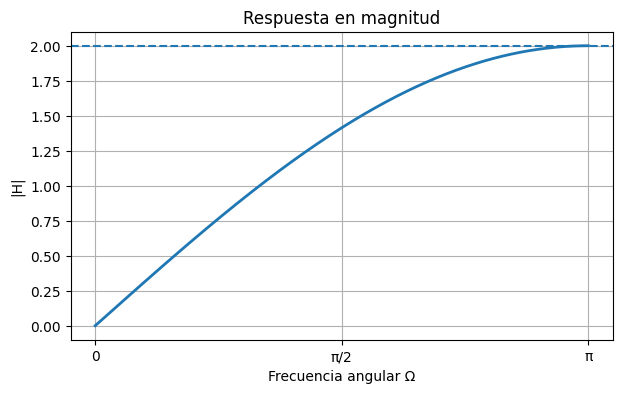

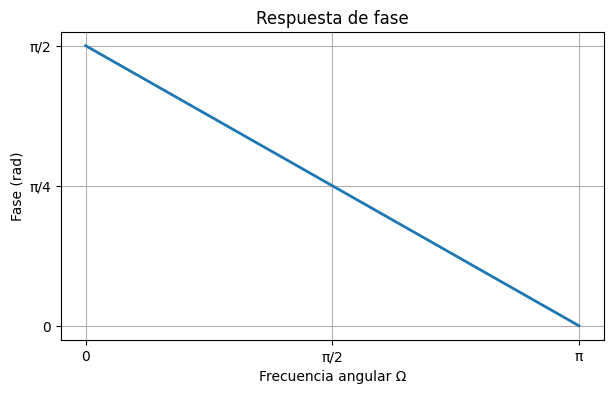

Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


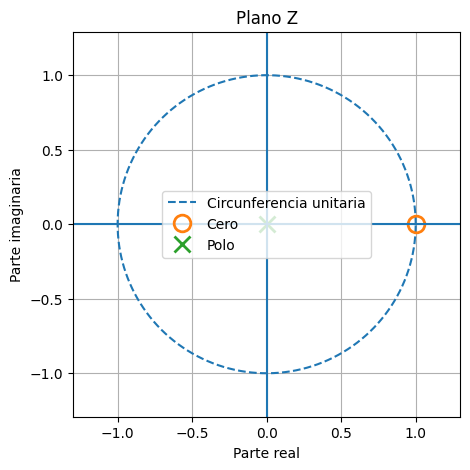

In [1]:

import numpy as np
import matplotlib.pyplot as plt

# Respuesta en frecuencia para A = 0
omega = np.linspace(0, np.pi, 500)
H = 1 - np.exp(-1j * omega)

magnitud = np.abs(H)
fase = np.pi/2 - omega/2

# Gráfico de magnitud
plt.figure(figsize=(7, 4))
plt.plot(omega, magnitud, linewidth=2)
plt.axhline(2, linestyle="--")
plt.xticks([0, np.pi/2, np.pi], ["0", "π/2", "π"])
plt.xlabel("Frecuencia angular Ω")
plt.ylabel("|H|")
plt.title("Respuesta en magnitud")
plt.grid(True)
plt.show()

# Gráfico de fase
plt.figure(figsize=(7, 4))
plt.plot(omega, fase, linewidth=2)
plt.xticks([0, np.pi/2, np.pi], ["0", "π/2", "π"])
plt.yticks([0, np.pi/4, np.pi/2], ["0", "π/4", "π/2"])
plt.xlabel("Frecuencia angular Ω")
plt.ylabel("Fase (rad)")
plt.title("Respuesta de fase")
plt.grid(True)
plt.show()

# Diagrama de polos y ceros
theta = np.linspace(0, 2*np.pi, 500)

plt.figure(figsize=(5, 5))
plt.plot(np.cos(theta), np.sin(theta), "--",
         label="Circunferencia unitaria")
plt.plot(1, 0, "o", markersize=12,
         markerfacecolor="none", markeredgewidth=2,
         label="Cero")
plt.plot(0, 0, "x", markersize=12,
         markeredgewidth=2, label="Polo")

plt.axhline(0)
plt.axvline(0)
plt.axis("equal")
plt.xlim(-1.3, 1.3)
plt.ylim(-1.3, 1.3)
plt.xlabel("Parte real")
plt.ylabel("Parte imaginaria")
plt.title("Plano Z")
plt.legend()
plt.grid(True)
plt.show()



##  Ecuación en diferencias del sistema

A partir de la función de transferencia:

$$
H(z)=\frac{z-1}{z-A}
=\frac{1-z^{-1}}{1-Az^{-1}}
$$

Separamos el sistema en dos etapas.

### Primera etapa

$$
T(z)=X(z)(1-z^{-1})
$$

Aplicando la transformada Z inversa:

$$
\boxed{t(n)=x(n)-x(n-1)}
$$

### Segunda etapa

$$
T(z)=Y(z)(1-Az^{-1})
$$

Aplicando la transformada Z inversa:

$$
\boxed{t(n)=y(n)-Ay(n-1)}
$$

### Ecuación en diferencias

Igualando ambas expresiones:

$$
x(n)-x(n-1)=y(n)-Ay(n-1)
$$

Despejando la salida:

$$
\boxed{y(n)=x(n)-x(n-1)+Ay(n-1)}
$$

### Conclusión

La salida depende de:

- La entrada actual $x(n)$.
- La entrada anterior $x(n-1)$.
- La salida anterior $y(n-1)$, multiplicada por $A$.

Por lo tanto, el sistema mantiene **un retardo en la entrada y otro en la realimentación**.

Para $A=0$, desaparece la realimentación y queda:

$$
\boxed{y(n)=x(n)-x(n-1)}
$$

que corresponde al filtro pasa altos de primer orden.



![Ejercicio 1](imagenes/ejercicio1.png)

## ejercico con un sólo retardo

![Dibujo A](imagenes/dibujoA.png)



# Ejercicio 2 — Síntesis de una red LC

Se conoce la respuesta en transmisión:

$$
|S_{21}(j\omega)|^2=\frac{\omega^4}{\omega^4+4}
$$

Con resistencias de fuente y carga normalizadas:

$$
R_g=R_L=1\ \Omega
$$

## Obtención de $S_{11}(s)$

Como la red es LC y no presenta pérdidas:

$$
|S_{11}|^2+|S_{21}|^2=1
$$

Por lo tanto:

$$
|S_{11}(j\omega)|^2
=1-\frac{\omega^4}{\omega^4+4}
=\frac{4}{\omega^4+4}
$$

Utilizando $s=j\omega$, se obtiene:

$$
S_{11}(s)S_{11}(-s)=\frac{4}{s^4+4}
$$

Proponemos:

$$
S_{11}(s)=\frac{2}{s^2+as+b}
$$

Entonces:

$$
(s^2+as+b)(s^2-as+b)
=s^4+(2b-a^2)s^2+b^2
$$

Igualando coeficientes:

$$
2b-a^2=0,\qquad b^2=4
$$

De donde:

$$
a=2,\qquad b=2
$$

Finalmente:

$$
\boxed{S_{11}(s)=\frac{2}{s^2+2s+2}}
$$

## Obtención de la impedancia de entrada

La relación entre el parámetro de reflexión y la impedancia es:

$$
S_{11}(s)=\frac{Z_{in}(s)-Z_0}{Z_{in}(s)+Z_0}
$$

Como $Z_0=1\ \Omega$:

$$
Z_{in}(s)=\frac{1+S_{11}(s)}{1-S_{11}(s)}
$$

Reemplazando:

$$
Z_{in}(s)=
\frac{1+\frac{2}{s^2+2s+2}}
{1-\frac{2}{s^2+2s+2}}
$$

Simplificando:

$$
\boxed{Z_{in}(s)=\frac{s^2+2s+4}{s^2+2s}}
$$

## Síntesis de la impedancia

Separamos la impedancia:

$$
Z_{in}(s)=1+\frac{4}{s(s+2)}
$$

La primera parte corresponde a la resistencia de carga:

$$
R_L=1\ \Omega
$$

Para el término restante:

$$
Z_{LC}(s)=\frac{4}{s(s+2)}
$$

Invertimos para obtener la admitancia:

$$
Y_{LC}(s)=\frac{s(s+2)}{4}
$$

Separando:

$$
Y_{LC}(s)=\frac{s^2}{4}+\frac{s}{2}
$$

La síntesis equivalente se realiza mediante un capacitor en serie y un inductor en paralelo con la carga:

$$
Z_{in}(s)=\frac{2}{s}+
\frac{s/2}{1+s/2}
$$

Identificamos:

$$
\frac{1}{sC}=\frac{2}{s}
\quad\Rightarrow\quad
\boxed{C=\frac12\ \mathrm{F}}
$$

$$
sL=\frac{s}{2}
\quad\Rightarrow\quad
\boxed{L=\frac12\ \mathrm{H}}
$$

## Resultado

Los componentes obtenidos son:

$$
\boxed{
R_g=1\ \Omega,\quad
R_L=1\ \Omega,\quad
C=\frac12\ \mathrm{F},\quad
L=\frac12\ \mathrm{H}
}
$$

La topología final consiste en un capacitor en serie, seguido de un inductor en paralelo con la resistencia de carga.



# Ejercicio 3 — Síntesis de impedancia a partir de $S_{11}$

## Obtención de la impedancia de entrada

Partimos de la relación:

$$
S_{11}(s)=\frac{Z_{in}(s)-R_0}{Z_{in}(s)+R_0}
$$

Despejando:

$$
\boxed{Z_{in}(s)=R_0\frac{1+S_{11}(s)}{1-S_{11}(s)}}
$$

Se conoce:

$$
S_{11}(s)=\frac{20s^2+12s+2}{30s^2+14s+4}
$$

Reemplazando y simplificando:

$$
Z_{in}(s)=R_0
\frac{50s^2+26s+6}{10s^2+2s+2}
$$

Por lo tanto:

$$
\boxed{
Z_{in}(s)=R_0\frac{25s^2+13s+3}{5s^2+s+1}
}
$$

## Identificación de las resistencias

Evaluamos los límites de la impedancia:

$$
\lim_{s\to 0}Z_{in}(s)=3R_0
$$

$$
\lim_{s\to\infty}Z_{in}(s)=5R_0
$$

Según la topología del circuito:

$$
R_1=3R_0
$$

$$
R_1+R_2=5R_0
$$

Entonces:

$$
\boxed{R_2=2R_0}
$$

## Obtención de la impedancia restante

Separamos la resistencia $R_1$:

$$
Z_1(s)=Z_{in}(s)-R_1
$$

$$
Z_1(s)=R_0\frac{10s^2+10s}{5s^2+s+1}
$$

Invertimos para obtener la admitancia:

$$
Y_1(s)=\frac{1}{Z_1(s)}
$$

Para el circuito formado por el inductor en paralelo con la rama serie $R_2-C$:

$$
Y_1(s)=\frac{1}{sL}+\frac{1}{R_2+\frac{1}{sC}}
$$

Simplificando:

$$
Y_1(s)=\frac{s^2R_2LC+sL+1}
{s^2LC+sR_2C}
$$

Por lo tanto:

$$
Z_1(s)=\frac{s^2LC+sR_2C}
{s^2R_2LC+sL+1}
$$

Igualamos con la impedancia obtenida:

$$
\frac{s^2LC+sR_2C}
{s^2R_2LC+sL+1}
=
R_0\frac{10s^2+10s}{5s^2+s+1}
$$

## Obtención de los componentes

Tomando $R_0=1\ \Omega$ e igualando coeficientes:

$$
L=10
$$

$$
LC=5
\quad\Rightarrow\quad
C=\frac{5}{10}=\frac12
$$

$$
R_2C=1
\quad\Rightarrow\quad
R_2=\frac{1}{C}=2
$$

Finalmente:

$$
R_1=3
$$

## Resultado final

$$
\boxed{
R_1=3\ \Omega,\qquad
R_2=2\ \Omega
}
$$

$$
\boxed{
L=10\ \mathrm{H},\qquad
C=\frac12\ \mathrm{F}
}
$$

La topología corresponde a una resistencia $R_1$ en serie con el paralelo de:

- Un inductor $L$.
- Una rama formada por $R_2$ y $C$ en serie.



# Ejercicio 4 — Síntesis de una transimpedancia

Se desea sintetizar una red LC cuya transimpedancia sea:

$$
Z(s)=\frac{V_2(s)}{I_g(s)}=k\frac{P(s)}{Q(s)}
$$

Las condiciones son:

- Ceros de transmisión en $\omega=0$ y $\omega=1/4$.
- Respuesta de máxima planicidad con 3 dB en la banda de paso.
- Salida en circuito abierto: $I_2=0$.

## Función de transferencia

Los ceros de transmisión determinan el numerador:

$$
P(s)=s\left(s^2+\frac{1}{16}\right)
$$

Para el denominador se utiliza:

$$
Q(s)=s^3+2s^2+2s+1
$$

Factorizando:

$$
Q(s)=(s+1)(s^2+s+1)
$$

Por lo tanto:

$$
\boxed{
Z(s)=k\frac{s\left(s^2+\frac{1}{16}\right)}
{s^3+2s^2+2s+1}
}
$$

## Relación entre la transimpedancia y $Z_{21}$

La transimpedancia se define como:

$$
Z(s)=\left.\frac{V_2}{I_g}\right|_{I_2=0}
$$

Por división de corriente en la entrada:

$$
I_1=I_g\frac{R_g}{R_g+Z_{11}}
$$

Entonces:

$$
\frac{I_1}{I_g}=\frac{1}{1+\frac{Z_{11}}{R_g}}
$$

Como:

$$
Z_{21}=\left.\frac{V_2}{I_1}\right|_{I_2=0}
$$

Resulta:

$$
Z(s)=\frac{V_2}{I_1}\frac{I_1}{I_g}
$$

Por lo tanto:

$$
\boxed{
Z(s)=\frac{Z_{21}(s)}
{1+\frac{Z_{11}(s)}{R_g}}
}
$$

## Normalización

Tomando:

$$
R_g=1
$$

Se obtiene:

$$
Z(s)=\frac{Z_{21}(s)}{1+Z_{11}(s)}
$$

En los apuntes se propone:

$$
Z_{21}(s)=\frac{s\left(s^2+\frac14\right)}
{2s^2+1}
$$

$$
Z_{11}(s)=\frac{s(s^2+2)}
{2s^2+1}
$$

Sustituyendo:

$$
Z(s)=
\frac{s\left(s^2+\frac14\right)}
{2s^2+1}
\cdot
\frac{1}{1+\frac{s^3+2s}{2s^2+1}}
$$

Simplificando:

$$
\boxed{
Z(s)=\frac{s\left(s^2+\frac14\right)}
{s^3+2s^2+2s+1}
}
$$


### Síntesis del circuito

![Síntesis del circuito](imagenes/sintesis.png)



### b) Síntesis de la impedancia

Partimos de:

$$
Z_{11}(s)=\frac{s(s^2+2)}{2s^2+1}
$$

Extraemos el primer inductor mediante:

$$
\frac{1}{L_1}=
\lim_{s^2\to-1/16}
\frac{2s^2+1}{s^2+2}
=\frac{14}{31}
$$

Por lo tanto:

$$
\boxed{L_1=\frac{31}{14}}
$$

La admitancia restante es:

$$
Y_2(s)=\frac{2s^2+1}{s(s^2+2)}
-\frac{14}{31s}
$$

Simplificando:

$$
Y_2(s)=\frac{3}{31}
\frac{16s^2+1}{s(s^2+2)}
$$

Invertimos para obtener la impedancia:

$$
Z_2(s)=\frac{31}{48}
\frac{s(s^2+2)}{s^2+1/16}
$$

Extraemos el circuito resonante:

$$
2K_1=
\lim_{s^2\to-1/16}
\frac{31}{48}(s^2+2)
=\frac{961}{768}
$$

Restando el término extraído:

$$
Z_4(s)=Z_2(s)-
\frac{961}{768}\frac{s}{s^2+1/16}
$$

Simplificando:

$$
Z_4(s)=\frac{31}{48}s
$$

Por lo tanto, el inductor restante es:

$$
\boxed{L_2=\frac{31}{48}}
$$

Para el circuito resonante paralelo:

$$
\frac{1}{C_T}=2K_1=\frac{961}{768}
$$

$$
\boxed{C_T=\frac{768}{961}}
$$

Como:

$$
\omega_0^2=\frac{1}{L_TC_T}=\frac{1}{16}
$$

Obtenemos:

$$
L_T=\frac{16}{C_T}
$$

$$
\boxed{L_T=\frac{961}{48}}
$$

**Valores obtenidos:**

$$
\boxed{
L_1=\frac{31}{14},\quad
L_2=\frac{31}{48},\quad
L_T=\frac{961}{48},\quad
C_T=\frac{768}{961}
}
$$

### Circuito sintetizado

![Circuito sintetizado](imagenes/dibujoB.png)


### c) Verificación mediante matriz de transmisión

La transimpedancia que queremos verificar es:

$$
T(s)=\frac{V_2}{I_g}
=K\frac{s(s^2+1/16)}{s^3+2s^2+2s+1}
$$

Para verificar el circuito utilizamos matrices de transmisión.

**Matrices elementales:**

Para una impedancia serie:

$$
M_Z=\begin{pmatrix}1&Z\\0&1\end{pmatrix}
$$

Para una admitancia en paralelo:

$$
M_Y=\begin{pmatrix}1&0\\Y&1\end{pmatrix}
$$

La impedancia del circuito resonante paralelo es:

$$
Z_{LC}=\frac{1}{C_T}\frac{s}{s^2+1/(L_TC_T)}
$$

La matriz total resulta:

$$
M=
\begin{pmatrix}1&0\\1/R_g&1\end{pmatrix}
\begin{pmatrix}1&0\\1/(sL_1)&1\end{pmatrix}
\begin{pmatrix}1&Z_{LC}\\0&1\end{pmatrix}
\begin{pmatrix}1&0\\1/(sL_2)&1\end{pmatrix}
$$

Como la salida está en circuito abierto:

$$
I_2=0
$$

Entonces:

$$
I_g=CV_2
\qquad\Rightarrow\qquad
\boxed{\frac{V_2}{I_g}=\frac{1}{C}}
$$

**Multiplicando las matrices y simplificando:**

$$
C(s)=
\frac{
s^3L_1L_2L_TC_T+
s^2R_gL_TC_T(L_1+L_2)+
sL_2(L_1+L_T)+
R_g(L_1+L_2+L_T)
}{
R_gL_1L_2s(s^2L_TC_T+1)
}
$$

Por lo tanto:

$$
\boxed{
\frac{V_2}{I_g}=
\frac{
R_g\,s\left(s^2+\frac{1}{L_TC_T}\right)
}{
s^3+
\frac{R_g(L_1+L_2)}{L_1L_2}s^2+
\frac{L_1+L_T}{L_1L_TC_T}s+
\frac{R_g(L_1+L_2+L_T)}{L_1L_2L_TC_T}
}
}
$$

Comparando con la función propuesta:

$$
T(s)=K\frac{s(s^2+1/16)}{s^3+2s^2+2s+1}
$$

Identificamos:

$$
\boxed{K=R_g}
$$

La expresión obtenida permite verificar la respuesta del circuito sustituyendo los valores de los componentes.




---

### Resolución manuscrita del trabajo práctico

Se adjunta la resolución manuscrita completa del trabajo práctico.

📄 [Ver resolución manuscrita (PDF)](manuscrito/Tarea11.pdf)
